In [2]:
import pandas as pd
import numpy as np
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path

data_path = (
    Path.home()
    / "OneDrive"
    / "Documents"
    / "Data_Analyst_Portfolio"
    / "Project_01_Ecommerce_Sales"
    / "Data"
    / "Raw"
)

print("Folder exists:", data_path.exists())

files = list(data_path.glob("*.csv"))

print("Total CSV files:", len(files))

for file in files:
    print(file.name)

Folder exists: True
Total CSV files: 10
monthly_revenue.csv
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [4]:
# Load Orders dataset
orders = pd.read_csv(
    data_path / "olist_orders_dataset.csv"
)

# Load Order Items dataset
order_items = pd.read_csv(
    data_path / "olist_order_items_dataset.csv"
)

print("Orders dataset loaded!")
print("Order Items dataset loaded!")

Orders dataset loaded!
Order Items dataset loaded!


In [5]:
print("Orders dataset shape:", orders.shape)

print("Order Items dataset shape:", order_items.shape)

Orders dataset shape: (99441, 8)
Order Items dataset shape: (112650, 7)


In [6]:
display(orders.head())

display(order_items.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
print("ORDERS DATASET")
orders.info()

print("\nORDER ITEMS DATASET")
order_items.info()

ORDERS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

ORDER ITEMS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id 

In [8]:
print("Missing values in Orders:")
print(orders.isnull().sum())

print("\nMissing values in Order Items:")
print(order_items.isnull().sum())

Missing values in Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values in Order Items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [9]:
print("Orders duplicates:", orders.duplicated().sum())

print("Order Items duplicates:", order_items.duplicated().sum())

Orders duplicates: 0
Order Items duplicates: 0


In [10]:
print("Orders:", orders.shape)

print("Order Items:", order_items.shape)

Orders: (99441, 8)
Order Items: (112650, 7)


In [11]:
# Orders date columns
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert columns into datetime format
for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        errors="coerce"
    )

print("Orders date conversion completed!")

Orders date conversion completed!


In [12]:
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

print("Order Items date conversion completed!")

Order Items date conversion completed!


In [13]:
print(orders.dtypes)

print("\nOrder Items Data Types:")
print(order_items.dtypes)

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Order Items Data Types:
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object


In [14]:
from pathlib import Path

cleaned_path = data_path.parent / "cleaned"

cleaned_path.mkdir(parents=True, exist_ok=True)

orders.to_csv(
    cleaned_path / "orders_cleaned.csv",
    index=False
)

order_items.to_csv(
    cleaned_path / "order_items_cleaned.csv",
    index=False
)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!


In [15]:
# Count orders by status

status_counts = orders["order_status"].value_counts()

print(status_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [16]:
print("First order date:")
print(orders["order_purchase_timestamp"].min())

print("\nLast order date:")
print(orders["order_purchase_timestamp"].max())

First order date:
2016-09-04 21:15:19

Last order date:
2018-10-17 17:30:18


In [17]:
total_revenue = order_items["price"].sum()

print("Total Product Revenue: R$", round(total_revenue, 2))

Total Product Revenue: R$ 13591643.7


In [18]:
total_orders = order_items["order_id"].nunique()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)

print("Average Order Value: R$", round(average_order_value, 2))

Total Orders: 98666
Average Order Value: R$ 137.75


In [19]:
products = pd.read_csv(
    data_path / "olist_products_dataset.csv"
)

translation = pd.read_csv(
    data_path / "product_category_name_translation.csv"
)

print("Products:", products.shape)
print("Translation:", translation.shape)

Products: (32951, 9)
Translation: (71, 2)


In [20]:
# Merge order items with products
sales = order_items.merge(
    products,
    on="product_id",
    how="left"
)

# Add English category names
sales = sales.merge(
    translation,
    on="product_category_name",
    how="left"
)

display(sales.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,garden_tools


In [21]:
category_revenue = (
    sales.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue.head(10))

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64


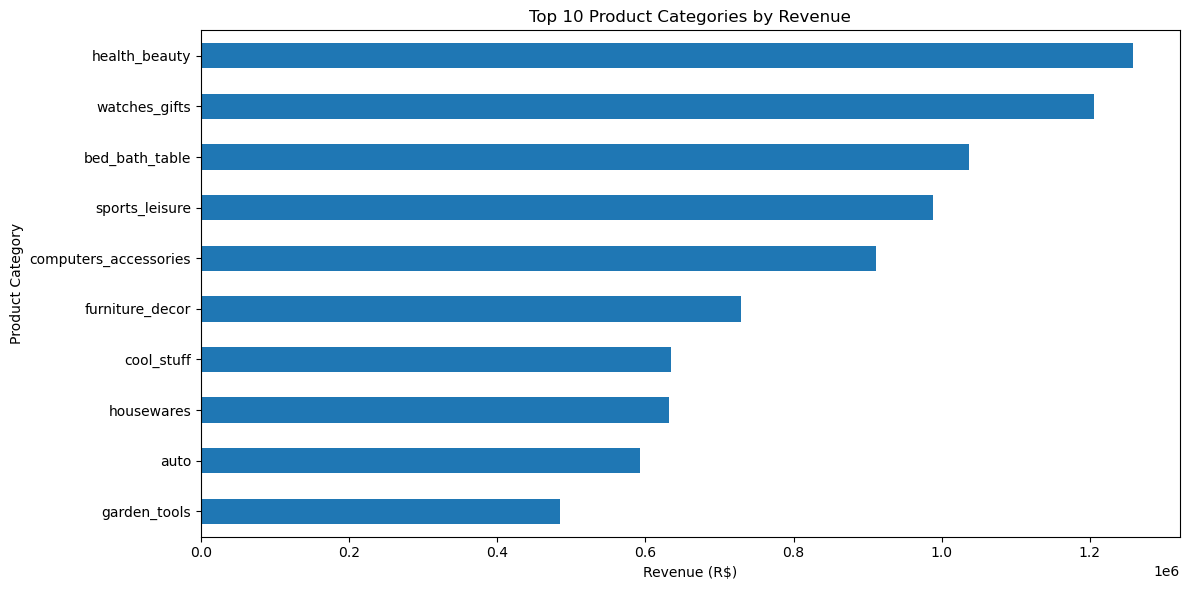

In [22]:
import matplotlib.pyplot as plt

top_categories = category_revenue.head(10)

plt.figure(figsize=(12, 6))

top_categories.sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [23]:
# Merge sales with order dates

monthly_sales = sales.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

# Extract year and month

monthly_sales["year_month"] = (
    monthly_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

print(monthly_sales.head())

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

  shipping_limit_date   price  freight_value product_category_name  \
0 2017-09-19 09:45:35   58.90          13.29            cool_stuff   
1 2017-05-03 11:05:13  239.90          19.93              pet_shop   
2 2018-01-18 14:48:30  199

In [24]:
monthly_revenue = (
    monthly_sales.groupby("year_month")["price"]
    .sum()
)

print(monthly_revenue)

year_month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: price, dtype: float64


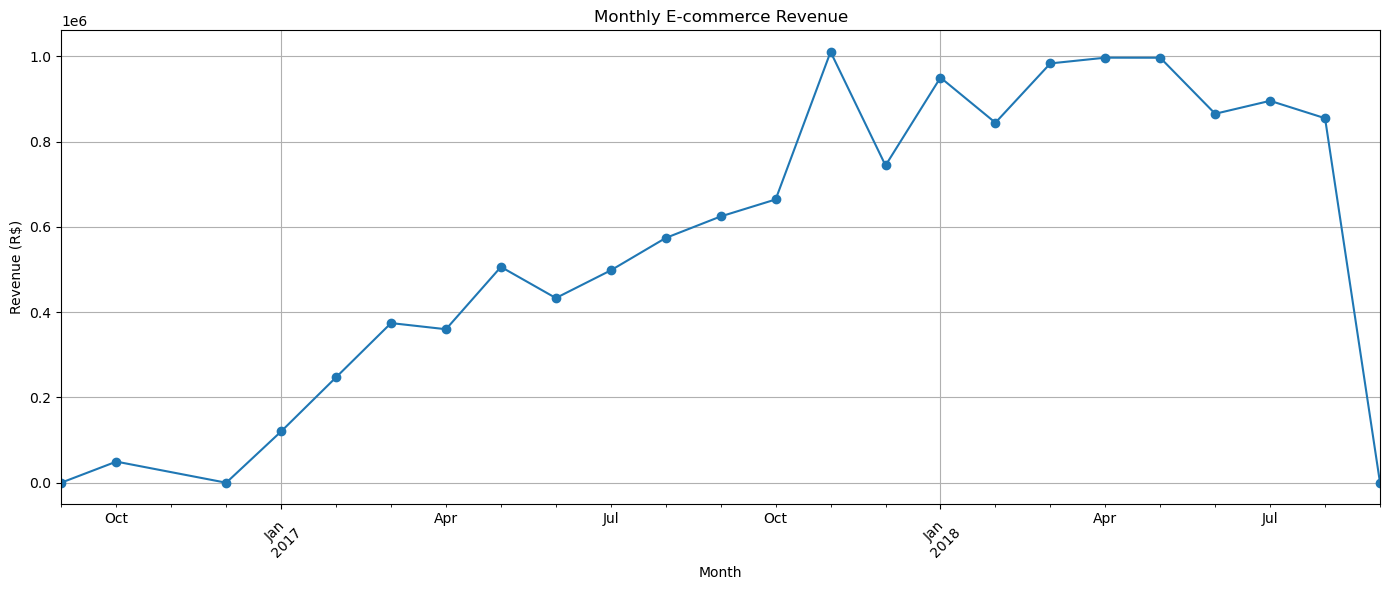

In [25]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly E-commerce Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [28]:
customers = pd.read_csv(
    data_path / "olist_customers_dataset.csv"
)

print("Customers dataset loaded successfully!")
print(customers.head())

Customers dataset loaded successfully!
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  


In [29]:
# Merge sales with order and customer information

regional_sales = sales.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

regional_sales = regional_sales.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

display(regional_sales.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,customer_id,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff,3ce436f183e68e07877b285a838db11a,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor,6489ae5e4333f3693df5ad4372dab6d3,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,perfumery,d4eb9395c8c0431ee92fce09860c5a06,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,garden_tools,58dbd0b2d70206bf40e62cd34e84d795,SP


In [30]:
state_revenue = (
    regional_sales.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 States by Revenue:")
print(state_revenue.head(10))

Top 10 States by Revenue:
customer_state
SP    5202955.05
RJ    1824092.67
MG    1585308.03
RS     750304.02
PR     683083.76
SC     520553.34
BA     511349.99
DF     302603.94
GO     294591.95
ES     275037.31
Name: price, dtype: float64


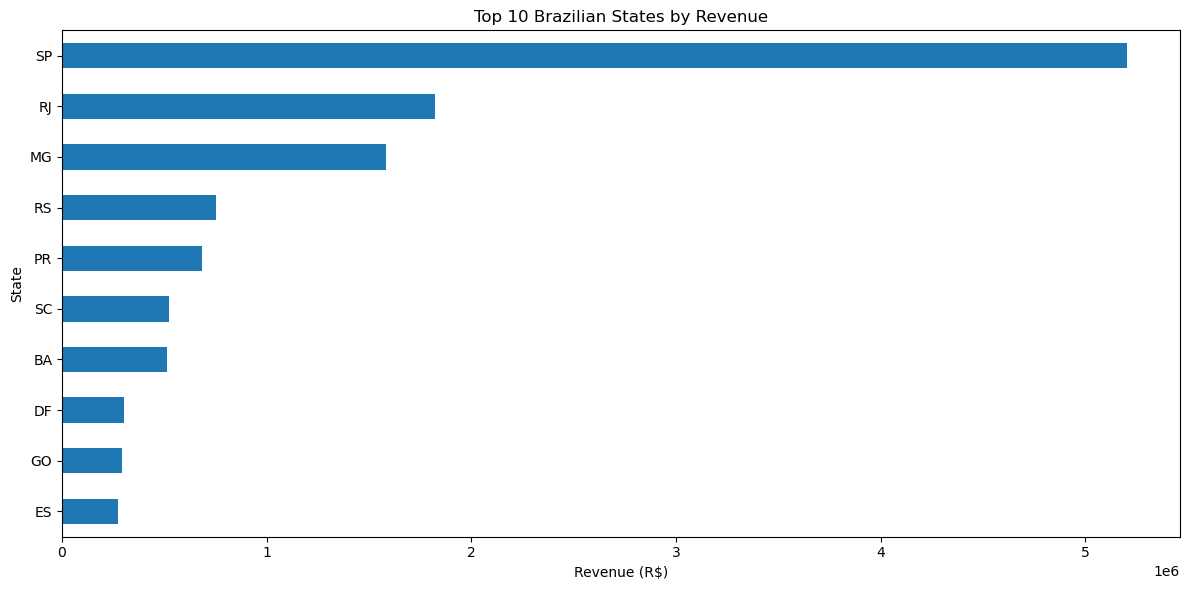

In [31]:
plt.figure(figsize=(12, 6))

state_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Brazilian States by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [32]:
# Customer analysis

customer_sales = sales.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

customer_sales = customer_sales.merge(
    customers,
    on="customer_id",
    how="left"
)

display(customer_sales.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,...,650.0,28.0,9.0,14.0,cool_stuff,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,...,30000.0,50.0,30.0,40.0,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,...,3050.0,33.0,13.0,33.0,furniture_decor,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,...,200.0,16.0,10.0,15.0,perfumery,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,...,3750.0,35.0,40.0,30.0,garden_tools,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP


In [33]:
# Calculate total spending per customer

customer_revenue = (
    customer_sales.groupby("customer_unique_id")["price"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Spending:")
print(customer_revenue.head(10))

Top 10 Customers by Spending:
customer_unique_id
0a0a92112bd4c708ca5fde585afaa872    13440.0
da122df9eeddfedc1dc1f5349a1a690c     7388.0
763c8b1c9c68a0229c42c9fc6f662b93     7160.0
dc4802a71eae9be1dd28f5d788ceb526     6735.0
459bef486812aa25204be022145caa62     6729.0
ff4159b92c40ebe40454e3e6a7c35ed6     6499.0
4007669dec559734d6f53e029e360987     5934.6
eebb5dda148d3893cdaf5b5ca3040ccb     4690.0
5d0a2980b292d049061542014e8960bf     4599.9
48e1ac109decbb87765a3eade6854098     4590.0
Name: price, dtype: float64


In [34]:
total_customers = customer_sales["customer_unique_id"].nunique()

average_spending = customer_revenue.mean()

print("Total Customers:", total_customers)
print("Average Customer Spending: R$", round(average_spending, 2))

Total Customers: 95420
Average Customer Spending: R$ 142.44


In [35]:
# Count orders per customer

customer_orders = (
    customer_sales.groupby("customer_unique_id")["order_id"]
    .nunique()
)

# Identify repeat customers

repeat_customers = customer_orders[
    customer_orders > 1
]

print("Total Unique Customers:", len(customer_orders))

print("Repeat Customers:", len(repeat_customers))

print(
    "Repeat Customer Percentage:",
    round(len(repeat_customers) / len(customer_orders) * 100, 2),
    "%"
)

Total Unique Customers: 95420
Repeat Customers: 2913
Repeat Customer Percentage: 3.05 %


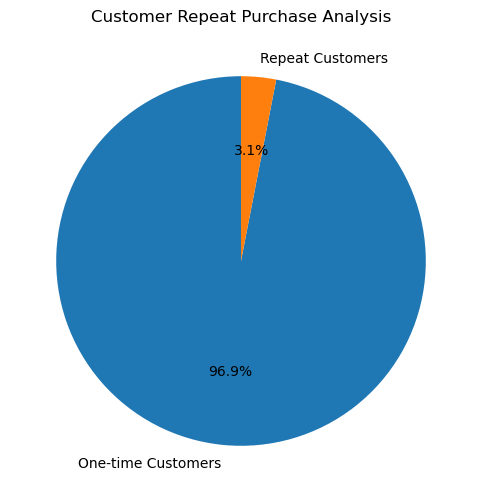

In [36]:
import matplotlib.pyplot as plt

one_time_customers = (
    len(customer_orders) - len(repeat_customers)
)

labels = ["One-time Customers", "Repeat Customers"]

values = [
    one_time_customers,
    len(repeat_customers)
]

plt.figure(figsize=(8, 6))

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Repeat Purchase Analysis")

plt.show()

In [37]:
# Load payment dataset

payments = pd.read_csv(
    data_path / "olist_order_payments_dataset.csv"
)

print("Payments Dataset:", payments.shape)
display(payments.head())

Payments Dataset: (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [38]:
print(payments.columns)

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')


In [39]:
payment_counts = payments["payment_type"].value_counts()

print(payment_counts)

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


In [40]:
payment_percentage = (
    payments["payment_type"].value_counts(normalize=True) * 100
)

print(payment_percentage.round(2))

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64


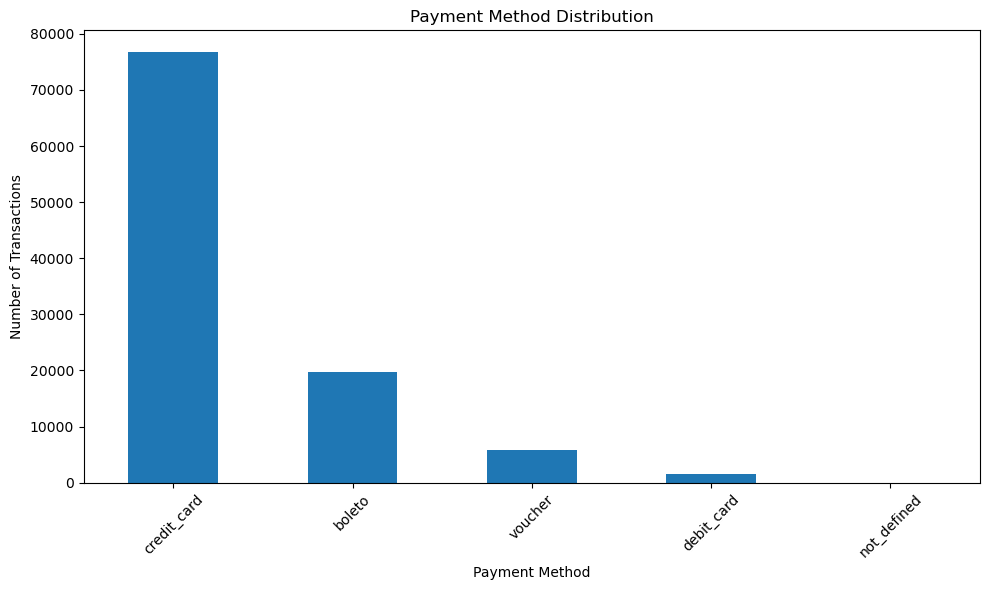

In [41]:
plt.figure(figsize=(10, 6))

payment_counts.plot(kind="bar")

plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
average_payment = payments.groupby(
    "payment_type"
)["payment_value"].mean().sort_values(ascending=False)

print("Average Payment Value:")
print(average_payment.round(2))

Average Payment Value:
payment_type
credit_card    163.32
boleto         145.03
debit_card     142.57
voucher         65.70
not_defined      0.00
Name: payment_value, dtype: float64


In [43]:
installment_analysis = payments.groupby(
    "payment_installments"
)["payment_value"].agg(["count", "mean", "sum"])

print(installment_analysis.head(15).round(2))

                      count    mean         sum
payment_installments                           
0                         2   94.32      188.63
1                     52546  112.42  5907233.36
2                     12413  127.23  1579283.03
3                     10461  142.54  1491103.80
4                      7098  163.98  1163907.61
5                      5239  183.47   961174.30
6                      3920  209.85   822611.81
7                      1626  187.67   305157.39
8                      4268  307.74  1313423.34
9                       644  203.44   131015.92
10                     5328  415.09  2211577.34
11                       23  124.93     2873.44
12                      133  321.68    42783.24
13                       16  150.46     2407.40
14                       15  167.96     2519.44


In [44]:
installment_counts = payments[
    "payment_installments"
].value_counts().sort_index()

print(installment_counts)

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64


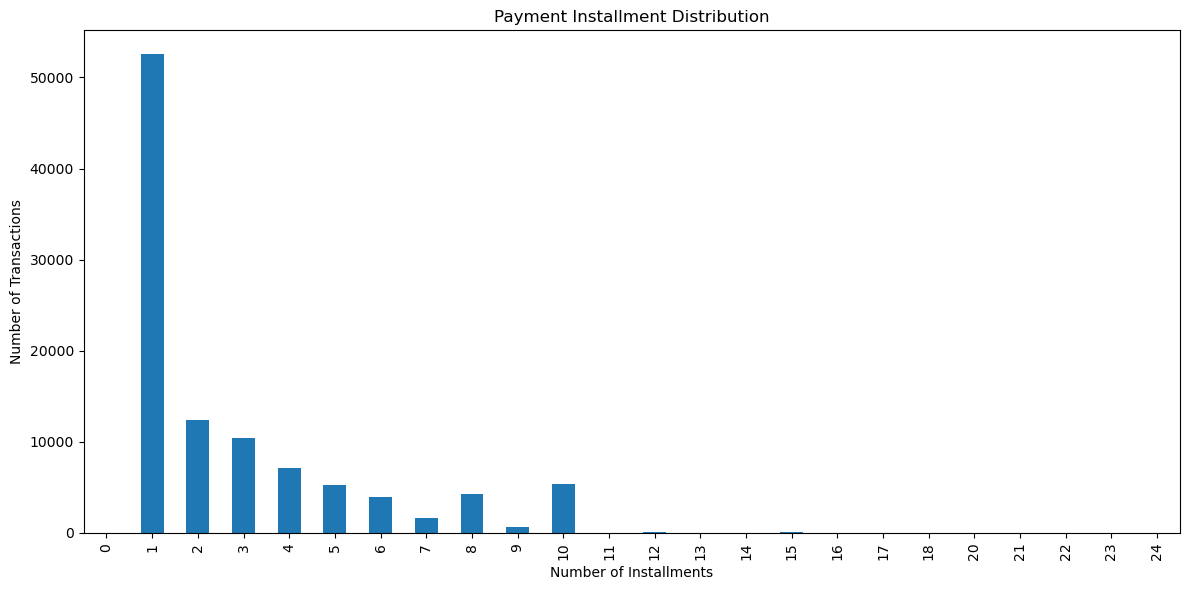

In [45]:
plt.figure(figsize=(12, 6))

installment_counts.plot(kind="bar")

plt.title("Payment Installment Distribution")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [46]:
payment_revenue = (
    payments.groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
)

print(payment_revenue.round(2))

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64


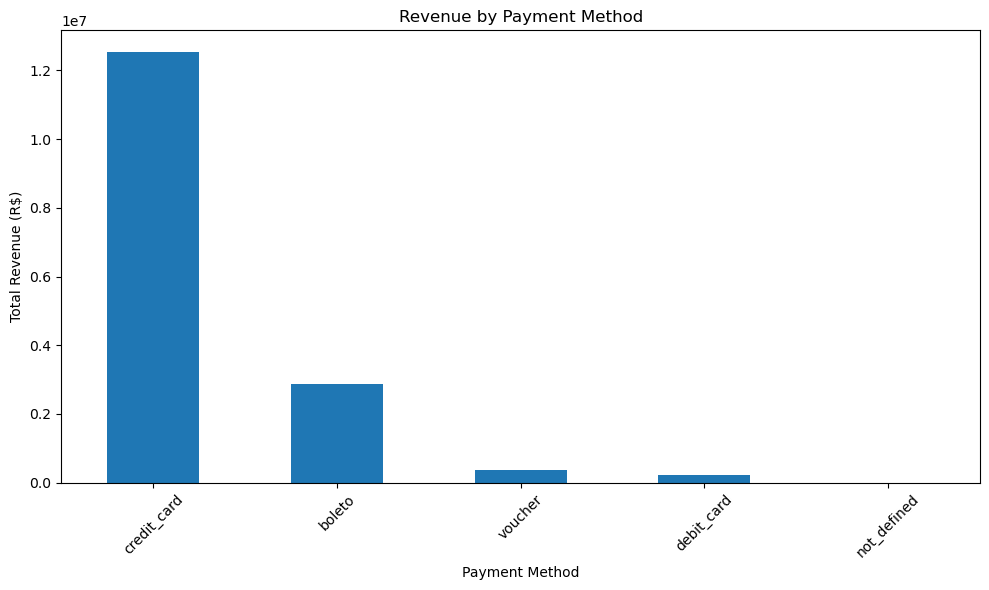

In [47]:
plt.figure(figsize=(10, 6))

payment_revenue.plot(kind="bar")

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Revenue (R$)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
# Order status analysis

order_status = orders["order_status"].value_counts()

print("Order Status Distribution:")
print(order_status)

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


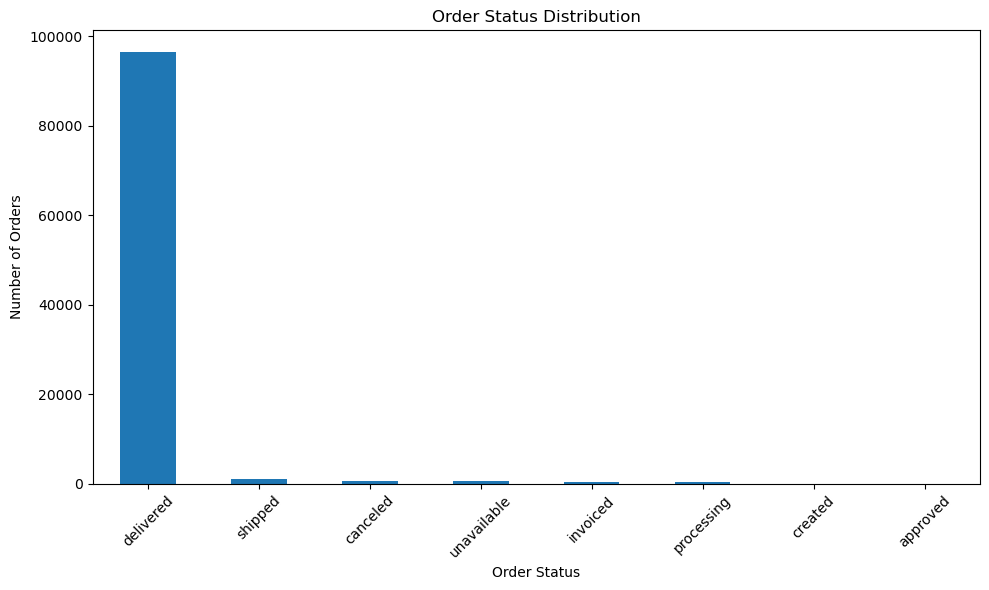

In [49]:
plt.figure(figsize=(10, 6))

order_status.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
order_percentage = (
    orders["order_status"]
    .value_counts(normalize=True) * 100
)

print(order_percentage.round(2))

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


In [51]:
# Delivery Performance Analysis

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders["order_delivered_customer_date"] = pd.to_datetime(
    delivered_orders["order_delivered_customer_date"]
)

delivered_orders["order_purchase_timestamp"] = pd.to_datetime(
    delivered_orders["order_purchase_timestamp"]
)

delivered_orders["order_estimated_delivery_date"] = pd.to_datetime(
    delivered_orders["order_estimated_delivery_date"]
)

print(delivered_orders[
    ["order_purchase_timestamp",
     "order_delivered_customer_date",
     "order_estimated_delivery_date"]
].head())

  order_purchase_timestamp order_delivered_customer_date  \
0      2017-10-02 10:56:33           2017-10-10 21:25:13   
1      2018-07-24 20:41:37           2018-08-07 15:27:45   
2      2018-08-08 08:38:49           2018-08-17 18:06:29   
3      2017-11-18 19:28:06           2017-12-02 00:28:42   
4      2018-02-13 21:18:39           2018-02-16 18:17:02   

  order_estimated_delivery_date  
0                    2017-10-18  
1                    2018-08-13  
2                    2018-09-04  
3                    2017-12-15  
4                    2018-02-26  


In [52]:
delivered_orders["actual_delivery_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.days

average_delivery = delivered_orders[
    "actual_delivery_days"
].mean()

print("Average Delivery Time:", round(average_delivery, 2), "days")

Average Delivery Time: 12.09 days


In [53]:
delivered_orders["delivery_difference"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivered_orders["delivery_status"] = delivered_orders[
    "delivery_difference"
].apply(
    lambda x: "Late" if x > 0 else "On Time"
)

print(delivered_orders["delivery_status"].value_counts())

print(
    delivered_orders["delivery_status"]
    .value_counts(normalize=True).mul(100).round(2)
)

delivery_status
On Time    88652
Late        7826
Name: count, dtype: int64
delivery_status
On Time    91.89
Late        8.11
Name: proportion, dtype: float64


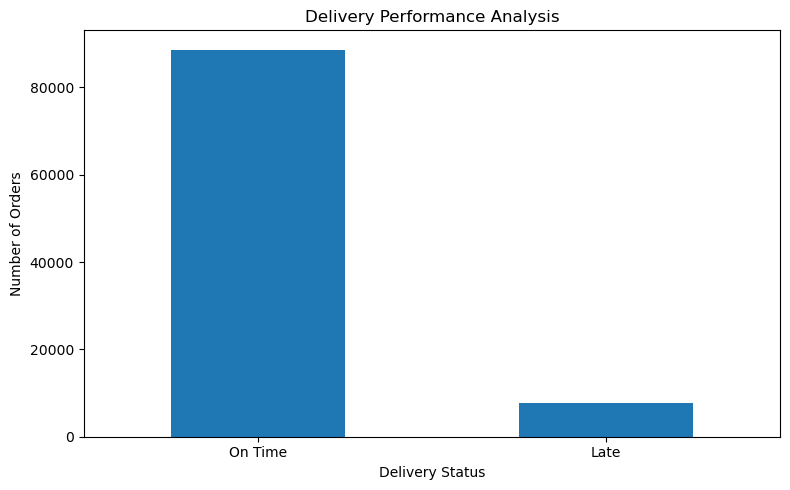

In [54]:
delivery_counts = delivered_orders["delivery_status"].value_counts()

plt.figure(figsize=(8, 5))

delivery_counts.plot(kind="bar")

plt.title("Delivery Performance Analysis")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:
print(sales.columns.tolist())
print(orders.columns.tolist())

['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english']
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [56]:
# Merge sales with order information

monthly_sales = sales.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

print(monthly_sales.head())

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

  shipping_limit_date   price  freight_value product_category_name  \
0 2017-09-19 09:45:35   58.90          13.29            cool_stuff   
1 2017-05-03 11:05:13  239.90          19.93              pet_shop   
2 2018-01-18 14:48:30  199

In [57]:
# Convert date column

monthly_sales["order_purchase_timestamp"] = pd.to_datetime(
    monthly_sales["order_purchase_timestamp"]
)

# Extract month

monthly_sales["month"] = (
    monthly_sales["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly revenue

monthly_revenue = (
    monthly_sales.groupby("month")["price"]
    .sum()
)

print(monthly_revenue)

month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: price, dtype: float64


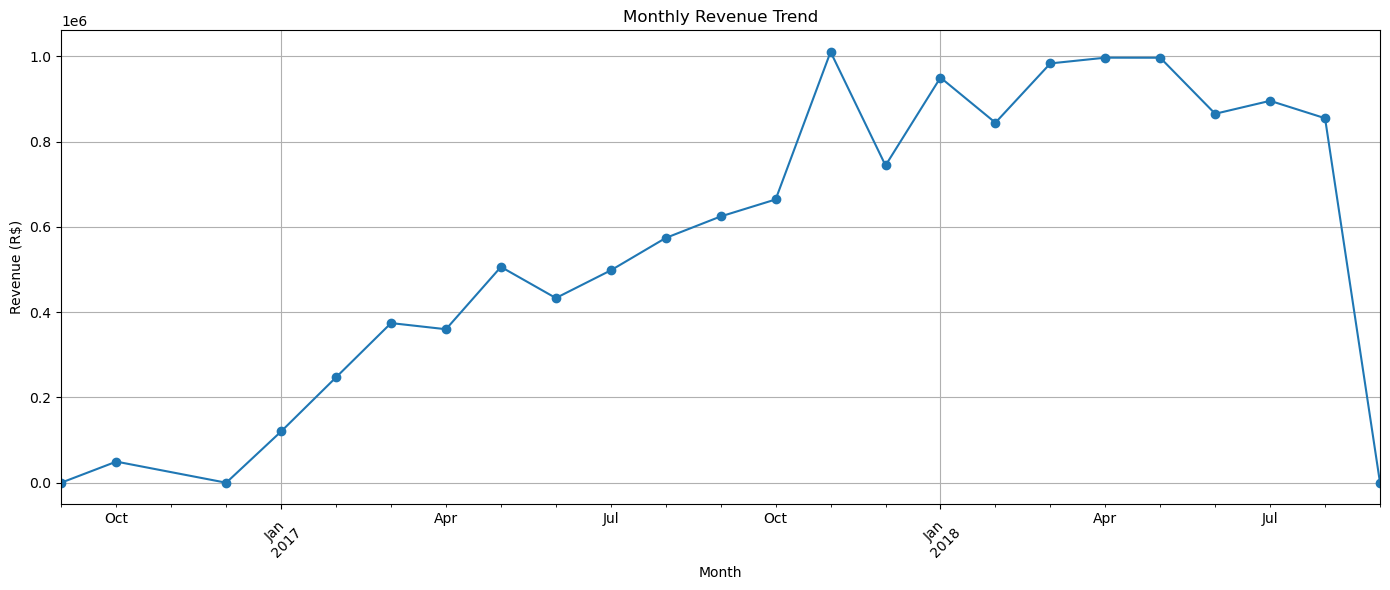

In [58]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [59]:
print("Highest Revenue Month:")
print(monthly_revenue.idxmax())
print("Revenue:", round(monthly_revenue.max(), 2))

print("\nLowest Revenue Month:")
print(monthly_revenue.idxmin())
print("Revenue:", round(monthly_revenue.min(), 2))

Highest Revenue Month:
2017-11
Revenue: 1010271.37

Lowest Revenue Month:
2016-12
Revenue: 10.9


In [60]:
# Export datasets for SQL analysis

sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
payments.to_csv("payments.csv", index=False)

print("All datasets exported successfully!")

All datasets exported successfully!


In [67]:
import os

for root, dirs, files in os.walk(os.path.expanduser("~")):
    if "monthly_revenue.csv" in files:
        print("File found:", os.path.join(root, "monthly_revenue.csv"))

File found: C:\Users\Hp\OneDrive\Documents\Data_Analyst_Portfolio\Project_01_Ecommerce_Sales\Data\Raw\monthly_revenue.csv


In [4]:
sales = pd.read_csv(r"C:\Users\Hp\OneDrive\Documents\Data_Analyst_Portfolio\Project_01_Ecommerce_Sales\Data\Raw\monthly_revenue.csv")

sales.head()

,month,monthly_revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02


In [5]:
print(sales.shape)
print(sales.columns)
print(sales.head())

(24, 2)
Index(['month', 'monthly_revenue'], dtype='object')
     month  monthly_revenue
0  2016-09           267.36
1  2016-10         49507.66
2  2016-12            10.90
3  2017-01        120312.87
4  2017-02        247303.02


In [7]:
best_month = sales.loc[
    sales["monthly_revenue"].idxmax()
]

print("Highest Revenue Month:", best_month["month"])
print("Revenue:", best_month["monthly_revenue"])

Highest Revenue Month: 2017-11
Revenue: 1010271.37


In [9]:
print(sales.head())
print(sales.columns)

     month  monthly_revenue
0  2016-09           267.36
1  2016-10         49507.66
2  2016-12            10.90
3  2017-01        120312.87
4  2017-02        247303.02
Index(['month', 'monthly_revenue'], dtype='object')


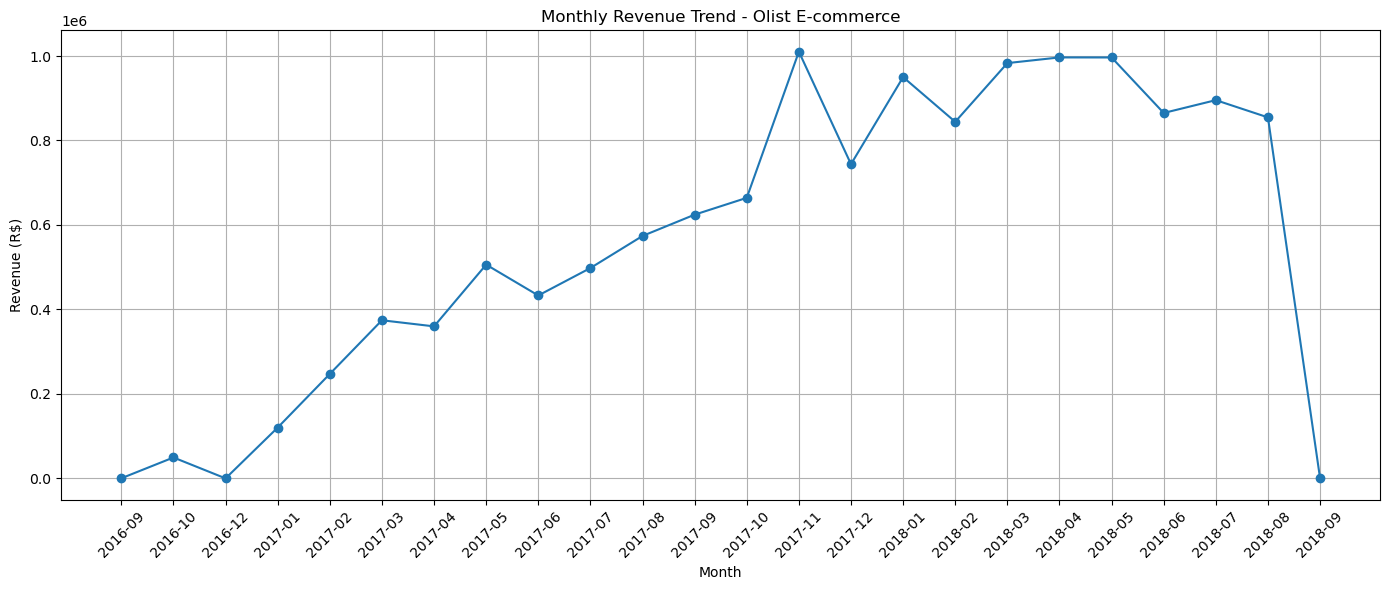

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    sales["month"],
    sales["monthly_revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend - Olist E-commerce")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd

category_sales = pd.read_csv(
    data_path / "top_10_categories.csv"
)

print(category_sales.head())

                category  total_revenue
0          health_beauty      963058.20
1          watches_gifts      893833.97
2         bed_bath_table      777609.92
3         sports_leisure      725526.75
4  computers_accessories      649809.74


In [12]:
print(category_sales.head())

                category  total_revenue
0          health_beauty      963058.20
1          watches_gifts      893833.97
2         bed_bath_table      777609.92
3         sports_leisure      725526.75
4  computers_accessories      649809.74


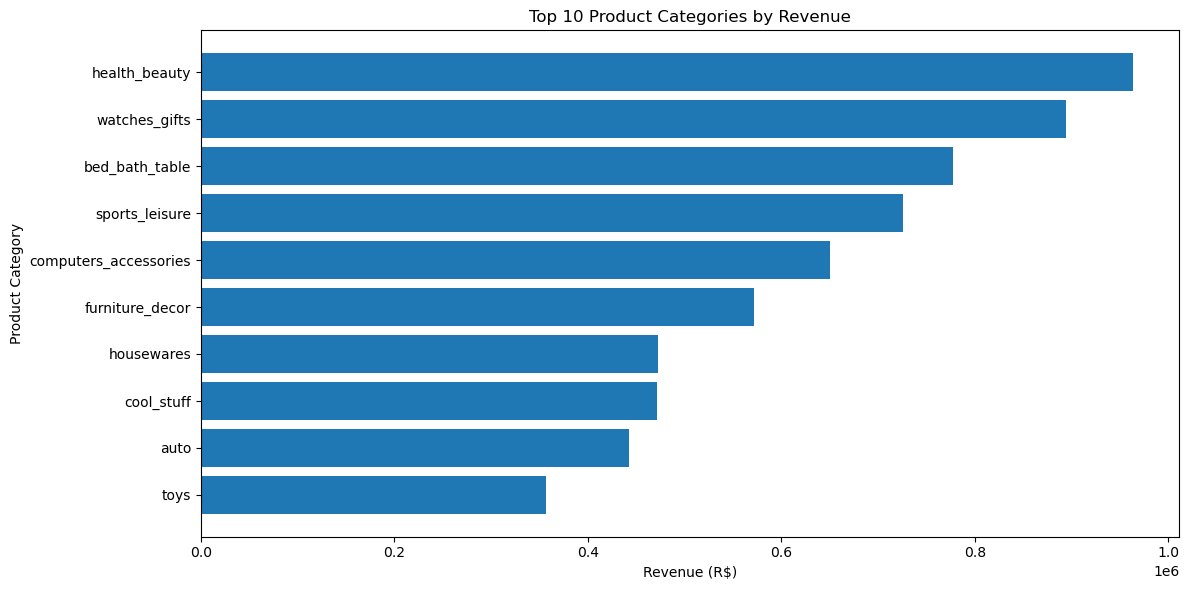

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    category_sales["category"],
    category_sales["total_revenue"]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [14]:
state_sales = pd.read_csv(
    data_path / "top_10_states.csv"
)

print(state_sales.head())

  customer_state  total_revenue
0             SP     5202955.05
1             RJ     1824092.67
2             MG     1585308.03
3             RS      750304.02
4             PR      683083.76


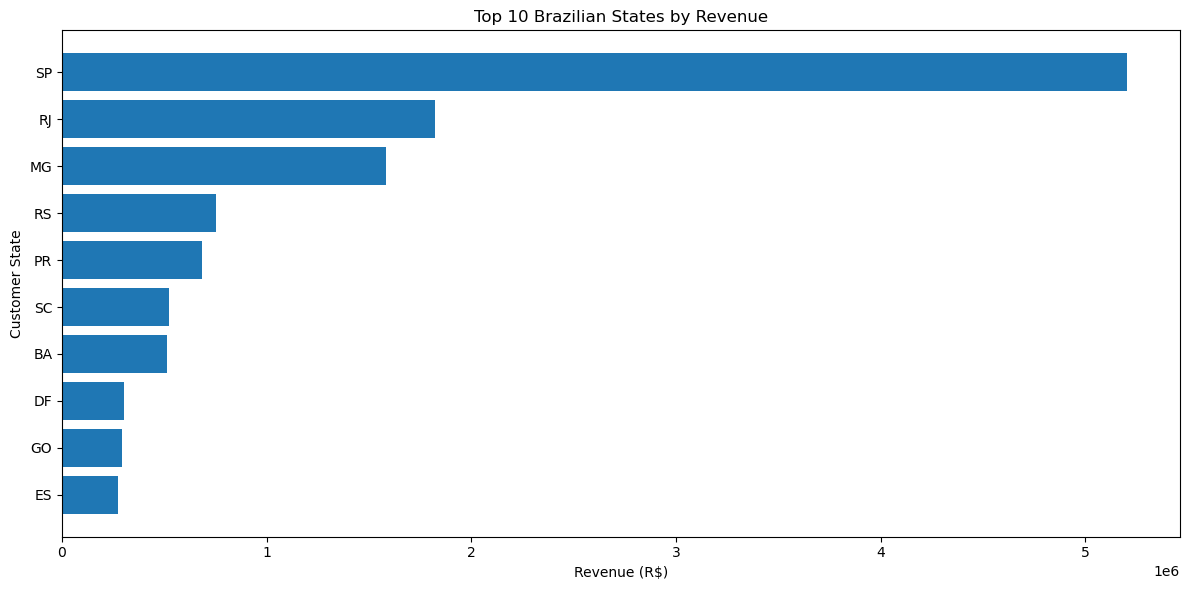

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    state_sales["customer_state"],
    state_sales["total_revenue"]
)

plt.title("Top 10 Brazilian States by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Customer State")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
payment_sales = pd.read_csv(
    data_path / "payment_analysis.csv"
)

print(payment_sales.head())

  payment_type  total_transactions  total_payment  average_payment
0  credit_card               76795    12542084.19           163.32
1       boleto               19784     2869361.27           145.03
2      voucher                5775      379436.87            65.70
3   debit_card                1529      217989.79           142.57
4  not_defined                   3           0.00             0.00


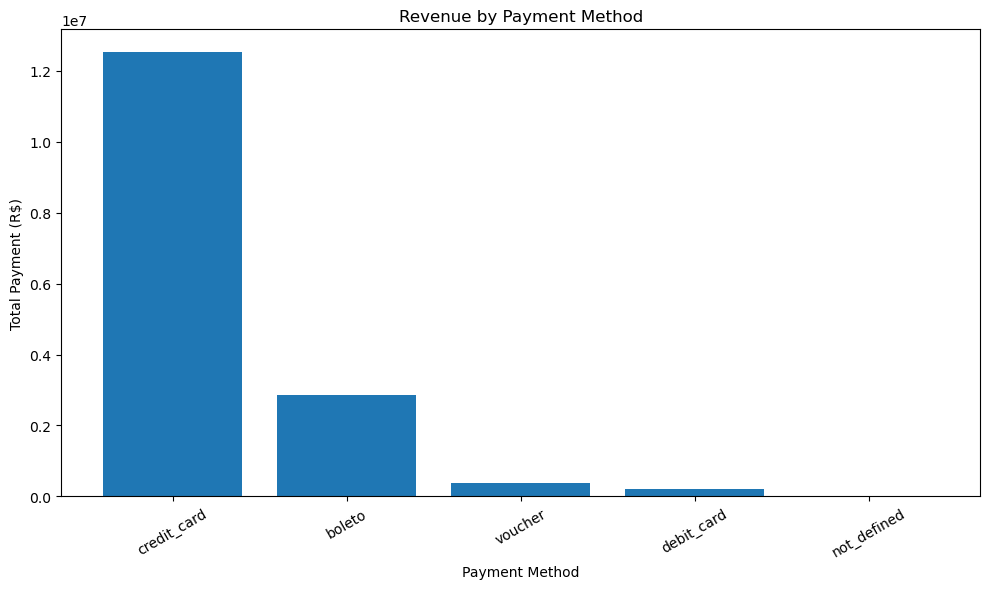

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    payment_sales["payment_type"],
    payment_sales["total_payment"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment (R$)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
customer_data = pd.read_csv(
    data_path / "customer_analysis.csv"
)

print(customer_data.head())

        customer_type  total_customers
0  One-Time Customers            93099
1    Repeat Customers             2997


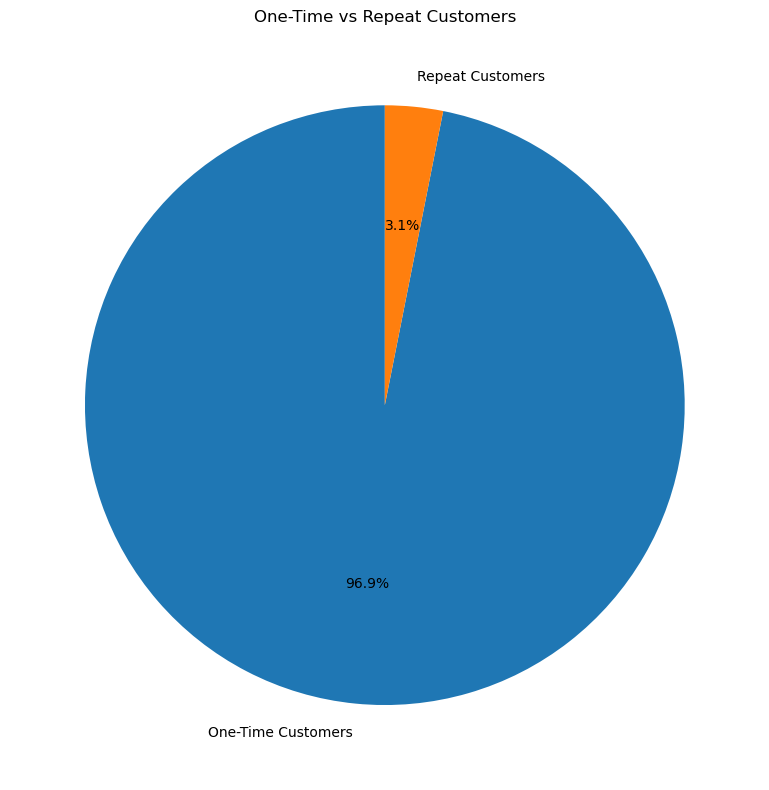

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.pie(
    customer_data["total_customers"],
    labels=customer_data["customer_type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("One-Time vs Repeat Customers")
plt.tight_layout()
plt.show()

In [20]:
delivery_data = pd.read_csv(
    data_path / "delivery_analysis.csv"
)

print(delivery_data.head())

    delivery_status  total_orders
0  On-Time Delivery         88652
1     Late Delivery          7826


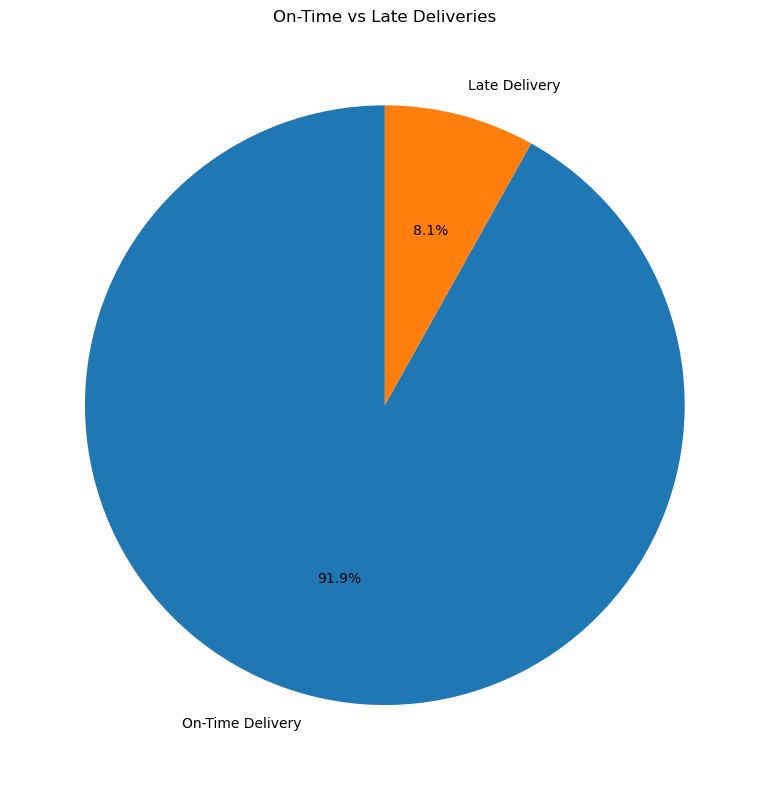

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.pie(
    delivery_data["total_orders"],
    labels=delivery_data["delivery_status"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("On-Time vs Late Deliveries")
plt.tight_layout()
plt.show()